In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

# These are the datasets from the data folder
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
pax = pd.read_csv(root / "data" / "raw" / "AA_PAX_FORECASTING.csv")
airports = pd.read_csv(root / "data" / "raw" / "AA_AIRPORT_INFO.csv")

# feature builder from pri's file 
def decimal_degrees(degrees, minutes, seconds, hemisphere):
    magnitude = degrees.astype(float) + minutes.astype(float) / 60 + seconds.astype(float) / 3600
    sign = hemisphere.astype(str).str.upper().map({"N": 1, "S": -1, "E": 1, "W": -1})
    return magnitude * sign

def airport_lookup(airports):
    lookup = pd.DataFrame(
        {
            "CITY_METRO_IATA_CD": airports["CITY_METRO_IATA_CD"].fillna("MISSING").to_numpy(),
            "STATE_PROVNC_CD": airports["STATE_PROVNC_CD"].fillna("MISSING").to_numpy(),
            "CNTRY_CD": airports["CNTRY_CD"].fillna("MISSING").to_numpy(),
            "WRLD_AREA_DOT_CD": airports["WRLD_AREA_DOT_CD"].astype("int64").astype(str).to_numpy(),
            "LAT": decimal_degrees(
                airports["LAT_DEGREE_QTY"],
                airports["LAT_MINUTE_QTY"],
                airports["LAT_SECOND_QTY"],
                airports["LAT_HEMSPHR_CD"],
            ).to_numpy(),
            "LNG": decimal_degrees(
                airports["LNGTD_DEGREE_QTY"],
                airports["LNGTD_MINUTE_QTY"],
                airports["LNGTD_SECOND_QTY"],
                airports["LNGTD_HEMSPHR_CD"],
            ).to_numpy(),
            "RUNWAY_FT": airports["LNGST_RUNWAY_FT_QTY"].replace(0, np.nan).to_numpy(),
            "ELEVATION_FT": airports["ELEVATN_FT_QTY"].to_numpy(),
        }
    )
    lookup.index = airports["AIRPRT_CD"].to_numpy()
    return lookup[~lookup.index.duplicated()]

def build_features(pax, airports):
    lookup = airport_lookup(airports)
    frame = pax.drop(columns=["Unnamed: 0", "SF_LOAD_TMS", "OD_REV_USD"]).copy()
    y = frame.pop("OD_PAX")
    month = frame["DEP_MONTH"].astype(int)
    features = frame.join(lookup.add_prefix("ORG_"), on="ORG_AIRPRT")
    features = features.join(lookup.add_prefix("DES_"), on="DES_AIRPRT")
    features["DEP_MONTH"] = month.astype(str)
    features["MONTH_SIN"] = np.sin(2 * np.pi * month / 12)
    features["MONTH_COS"] = np.cos(2 * np.pi * month / 12)
    categorical = [
        "DEP_MONTH", "ORG_AIRPRT", "DES_AIRPRT",
        "ORG_CITY_METRO_IATA_CD", "DES_CITY_METRO_IATA_CD",
        "ORG_STATE_PROVNC_CD", "DES_STATE_PROVNC_CD",
        "ORG_CNTRY_CD", "DES_CNTRY_CD",
        "ORG_WRLD_AREA_DOT_CD", "DES_WRLD_AREA_DOT_CD",
    ]
    for column in categorical:
        features[column] = features[column].astype("category")
    return features, y

X, y = build_features(pax, airports)
print(f"Loaded shared feature set: {X.shape[0]:,} rows and {X.shape[1]} features.")


Loaded shared feature set: 1,533,522 rows and 22 features.


In [6]:
# X and y into one monthly passenger timeline, apparently this is required for ARIMA modeling.
timeline = pd.DataFrame({
    "DEP_YEAR": X["DEP_YEAR"].astype(int),
    "DEP_MONTH": X["DEP_MONTH"].astype(int),
    "OD_PAX": y
})

monthly_df = (
    timeline.groupby(["DEP_YEAR", "DEP_MONTH"], as_index=False)["OD_PAX"]
    .sum()
    .sort_values(["DEP_YEAR", "DEP_MONTH"])
)

# turn Year and Month into a proper calendar date 
monthly_df["DATE"] = pd.to_datetime(
    monthly_df["DEP_YEAR"].astype(str) + "-" + monthly_df["DEP_MONTH"].astype(str).str.zfill(2) + "-01"
)
monthly = monthly_df.set_index("DATE").asfreq("MS")["OD_PAX"]

TEST_PERIODS = 24
train = monthly.iloc[:-TEST_PERIODS].copy()
test = monthly.iloc[-TEST_PERIODS:].copy()

print(f"Training dates: {train.index.min().date()} to {train.index.max().date()} ({len(train)} months)")
print(f"Testing dates:  {test.index.min().date()} to {test.index.max().date()} ({len(test)} months)")


Training dates: 2019-01-01 to 2024-07-01 (67 months)
Testing dates:  2024-08-01 to 2026-07-01 (24 months)


In [7]:
# Helper function to calculate MAE and RMSE
def get_scores(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
    }

def seasonal_naive(history, periods, season_length=12):
    values = list(history.astype(float))
    preds = []
    for _ in range(periods):
        val = values[-season_length] if len(values) >= season_length else values[-1]
        preds.append(val)
        values.append(val)
    return np.array(preds)

#  Seasonal Naive baseline
naive_pred = seasonal_naive(train, len(test))

# Run basic ARIMA(1, 1, 1) testing
arima_fit = ARIMA(train, order=(1, 1, 1)).fit()
arima_pred = arima_fit.forecast(steps=len(test))

# Seasonal SARIMAX(1, 1, 1)(1, 1, 1, 12) for yearly airline cycles
sarimax_fit = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False)
sarimax_pred = sarimax_fit.forecast(steps=len(test))

# 4. js displays all the scores for comparision.
scores_table = pd.DataFrame({
    "Seasonal Naive (Reference)": get_scores(test, naive_pred),
    "ARIMA(1, 1, 1)": get_scores(test, arima_pred),
    "SARIMAX(1, 1, 1)(1, 1, 1, 12)": get_scores(test, sarimax_pred),
}).T.sort_values("RMSE")

display(scores_table.round(2))


,MAE,RMSE
Seasonal Naive (Reference),3113174.10,4319584.87
"ARIMA(1, 1, 1)",9187860.27,10301932.82
"SARIMAX(1, 1, 1)(1, 1, 1, 12)",9135953.67,10790937.09


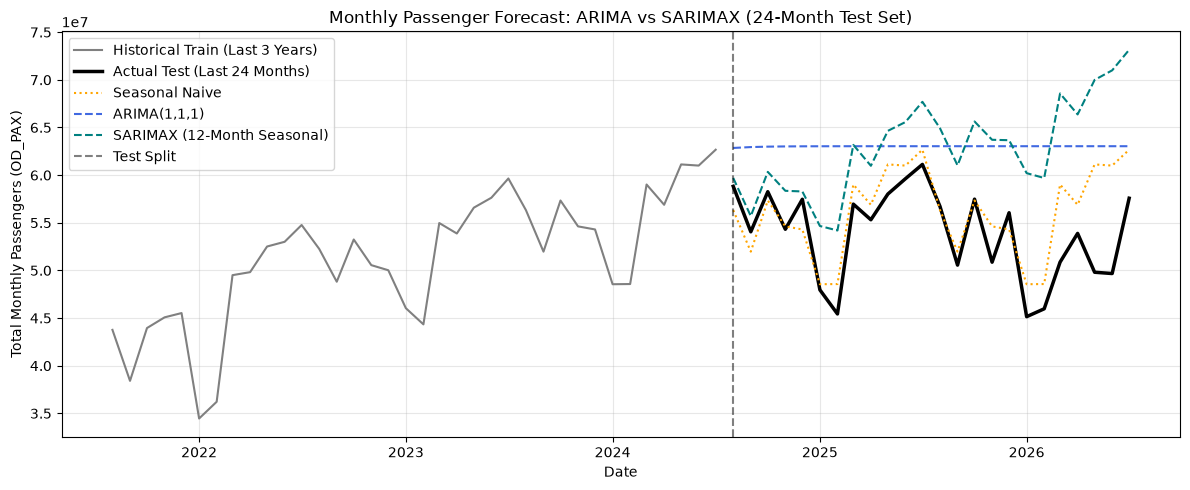

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(train.index[-36:], train.iloc[-36:], label="Historical Train (Last 3 Years)", color="gray")
plt.plot(test.index, test, label="Actual Test (Last 24 Months)", color="black", linewidth=2.5)
plt.plot(test.index, naive_pred, label="Seasonal Naive", linestyle=":", color="orange")
plt.plot(test.index, arima_pred, label="ARIMA(1,1,1)", linestyle="--", color="royalblue")
plt.plot(test.index, sarimax_pred, label="SARIMAX (12-Month Seasonal)", linestyle="--", color="teal")

plt.axvline(test.index[0], color="black", linestyle="--", alpha=0.5, label="Test Split")
plt.title("Monthly Passenger Forecast: ARIMA vs SARIMAX (24-Month Test Set)")
plt.xlabel("Date")
plt.ylabel("Total Monthly Passengers (OD_PAX)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Deliverable 4 Bake-Off Summary: ARIMA

* **My Scores:** I reported both **MAE** and **RMSE** in the table above using the exact same 24 month test period from our baseline so we can compare everything fairly.

* **Why Seasonality Matters (and Where ARIMA Struggles):** So basically, the regular `ARIMA(1,1,1)` model just draws a flat line and completely misses like the big summer and holiday travel spikes. Adding the 12 month seasonal part with `SARIMAX` actually catches the seasonal wave shape, though it ends up drifting too high because it assumes the past upward growth trend just keeps climbing forever instead of leveling off.

* **What Model We Should Pick:** The main catch with ARIMA is that it only works on one single timeline, so I had to add all the routes together into one monthly total and basically throw away all 20 airport and route columns from `X`. So while SARIMAX is interesting to look at for overall airline trends, we should definitely pick another model for this data.

